#**Personal Protective Equipment Detection Project**

**Training YOLO11 Object Detection Model on a Custom Dataset for PPE Detection**

* **Dataset Details:**
  * **Project Name:** PPE_Detection Computer Vision Model
  * **Dataset Size:** Contains **3,290 images** with bounding box annotations for safety gear.

I explored several datasets for my PPE detection project and found this one to be the most suitable and reliable for my requirements. Therefore, I decided to use it for my project. I found this dataset on the Roboflow website, and I have shared the link below for your review.

**Dataset Link:** https://universe.roboflow.com/project-uyrxf/ppe_detection-v1x3l/dataset/2

### 🖥️ Hardware Acceleration & GPU Verification

Before executing heavy deep learning tasks, we run the system interface command to verify our hardware accelerator profile.

* **Purpose:** Confirms the allocated GPU hardware profile, checks temperature constraints, and monitors active Video RAM (VRAM) overhead.
* **Why it matters:** Ensures the environment is properly utilizing CUDA-enabled acceleration for accelerated YOLO training speeds.


In [1]:
!nvidia-smi

Thu Oct 15 15:06:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 📦 Environment Setup & Library Installation

We initialize our workspace by installing the official **Ultralytics** library.

* **Purpose:** Installs the core Python framework required to initialize, fine-tune, and deploy YOLO architecture variants.
* **Dependencies:** Automatically sets up deep learning backend wrappers (including PyTorch and CUDA bindings) to guarantee efficient execution on our GPU hardware.


In [2]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 56.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 11.8 MB/s eta 0:00:00


### 🔍 Environment Diagnostic & GPU Verification

We execute the native Ultralytics check utility to perform a complete system diagnostic before processing our image and video pipelines.

* **Purpose:** Validates the exact software framework version, cross-references internal dependencies, and confirms proper CUDA acceleration linkages.
* **Why it matters:** Guarantees that our deep learning model has uninterrupted access to the GPU infrastructure, preventing runtime slowdowns during inference execution.


In [3]:
import ultralytics
ultralytics.checks()

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)


### 🛠️ Module Architecture & Library Dependencies

We import the essential framework components needed to load our neural network architecture and visualize pipeline outputs.

* **YOLO (Ultralytics):** The primary object detection class used to construct, load, and execute predictions using our custom weights.
* **Image (IPython.display):** A specialized notebook rendering utility that lets us display visual training charts, metric evaluations, and prediction images inline.


In [4]:
from ultralytics import YOLO
from IPython.display import Image

### 📥 Automated Dataset Ingestion via Roboflow API

We utilize the Roboflow Python SDK to securely authenticate, stream, and structure our target object detection dataset directly inside the runtime environment.

* **Authentication:** A dedicated API key establishes a verified connection to the public `ppe_detection-v1x3l` workspace.
* **Version Lock:** We explicitly isolate **Version 2** of the project to maintain complete consistency with our exploratory data audit.
* **Architecture Formatting:** The download payload is requested in the specialized `yolov11` structure. This completely bypasses manual data organizing by automatically partitioning our images, annotations, and mapping configurations (`data.yaml`) into plug-and-play directories.


In [5]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="sCoQ1oYiNNK5RxMwVs72")
project = rf.workspace("project-uyrxf").project("ppe_detection-v1x3l")
version = project.version(2)
dataset = version.download("yolov11")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 115.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.4 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PPE_Detection-2 in yolov11:: 100%|██████████| 6472/6472 [00:01<00:00, 6323.18it/s]


### 📂 Dataset Location Check

Prints the local folder path where Roboflow saved the downloaded dataset.

* **Purpose:** Confirms the download succeeded and shows the directory that holds the `train`, `valid` and `test` splits plus `data.yaml`.
* **Why it matters:** This path is reused as `{dataset.location}` in the training, validation and prediction commands below.

In [6]:
dataset.location

'/content/PPE_Detection-2'

### 🚀 Custom YOLO11n Neural Network Training Loop

We launch the model training loop to optimize our convolutional backbone weights on the custom personal protective equipment dataset.

* **Transfer Learning Foundation:** We load the lightweight `yolo11n.pt` pre-trained baseline framework to utilize robust feature extraction features.
* **Optimization Iterations:** The network parameters are exposed to the target training data subset for **40 complete epochs**, allowing the gradient descent optimizer to minimize loss metrics across localized bounding boxes.
* **Dimensional Constraints:** Input features are locked to a standard **640-pixel resolution scale** to strike a reliable balance between fine feature recognition (e.g., eye wear, gloves) and hardware memory limits.


In [7]:
!yolo task=detect mode=train data={dataset.location}/data.yaml \
model="yolo11n.pt" \
epochs=40 \
imgsz=640


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PPE_Detection-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, op

### 📈 Verification of Performance Curve Renderings

We execute a dedicated Python script to display our model's performance curves generated during the validation pass.

* **Recall-Confidence Curve:** Visualizes how effectively the network minimizes false negatives across classes as confidence criteria constraints are tightened.
* **Precision-Confidence Curve:** Demonstrates the purity of the model's classifications, indicating that as our operational threshold matches a higher confidence mark, the positive detection accuracy approaches a clean 100%.
* **Implementation Note:** Utilizing the `IPython.display` module avoids filesystem data-stream mismatches and allows direct visual inspection of data trends within the local workspace.


--- Recall Curve ---


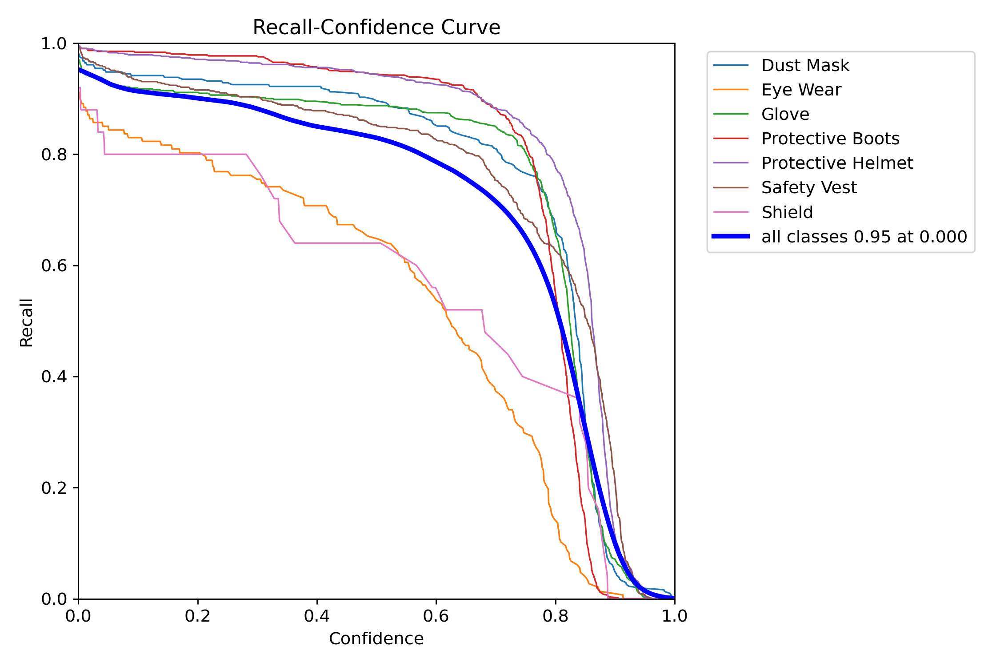


--- Precision Curve ---


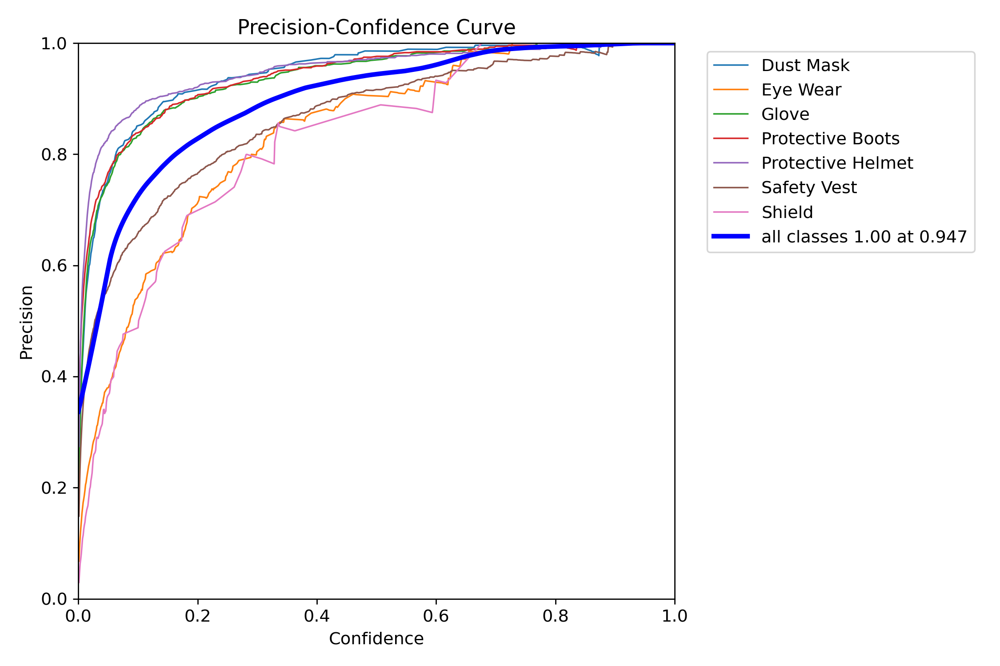

In [8]:
from IPython.display import Image, display

# Display the Recall curve
print("--- Recall Curve ---")
display(Image("/content/runs/detect/train/BoxR_curve.png", width=600))

# Display the Precision curve
print("\n--- Precision Curve ---")
display(Image("/content/runs/detect/train/BoxP_curve.png", width=600))



The model shows strong overall performance.  
- Recall remains high (>0.8) for most classes until confidence exceeds 0.6, indicating good detection coverage.  
- Precision steadily improves with confidence, reaching near 1.0 around 0.9, showing reliable predictions at higher thresholds.  
- Protective Helmet and Eye Wear perform best, while Glove and Boots drop earlier, suggesting room for improvement in those classes.

##**Confusion Matrix**

### 🧮 Confusion Matrix (Raw Counts)

Displays the confusion matrix saved by YOLO after training.

* **Purpose:** Shows, for every PPE class, how many objects were detected correctly (diagonal) versus confused with another class or with background (off-diagonal).
* **Why it matters:** Reveals which classes the model mixes up and where it misses objects entirely.

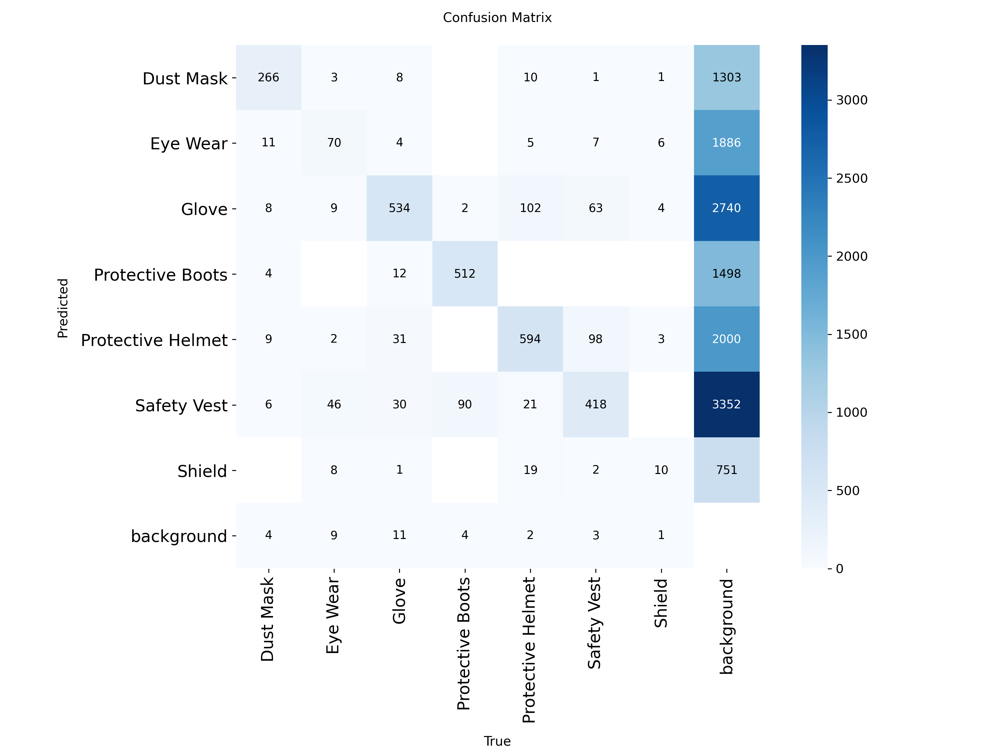

In [9]:
Image("/content/runs/detect/train/confusion_matrix.png", width=600)

### 🧮 Confusion Matrix (Normalized)

Displays the same confusion matrix, but scaled so each column sums to 1.

* **Purpose:** Converts raw counts into per-class proportions, making classes with very different sample sizes directly comparable.
* **Why it matters:** Easier to read class-wise accuracy and to spot weak classes in an imbalanced dataset.

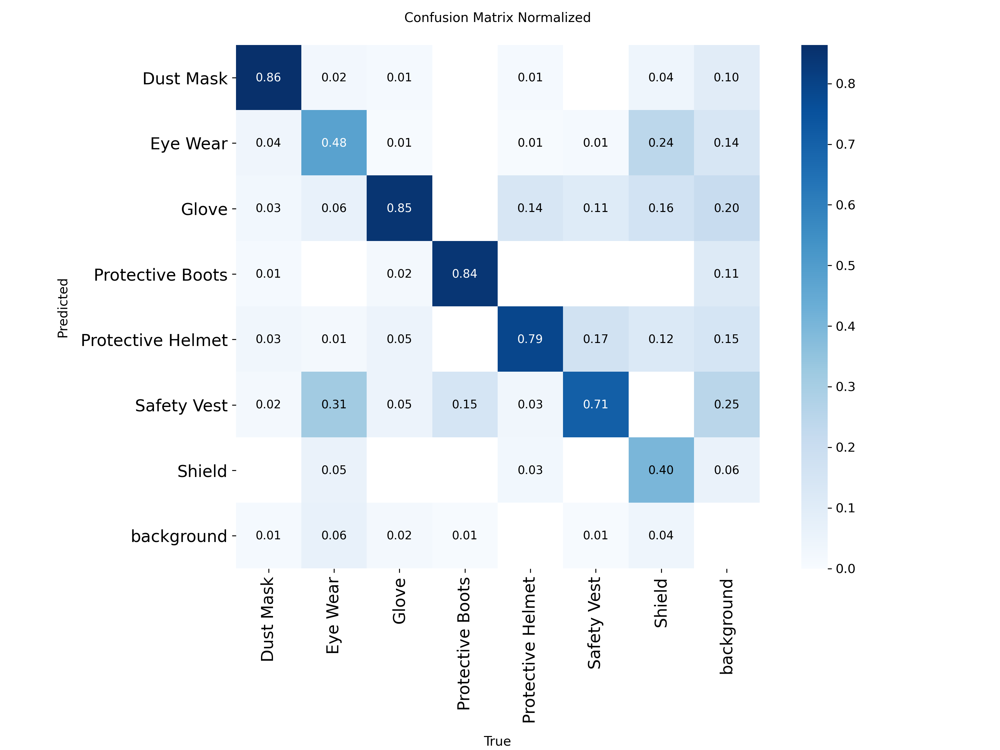

In [10]:
Image("/content/runs/detect/train/confusion_matrix_normalized.png", width=600)

The confusion matrices show that the model performs well overall but with some class imbalance.  
- High diagonal values in both matrices indicate strong accuracy for most protective equipment classes.  
- Normalized results show the model predicts Gloves and Protective Helmets most reliably (≈0.85 and 0.79).  
- Eye Wear and Dust Mask have lower normalized accuracy (≈0.48 and 0.69), suggesting these classes are more frequently misclassified.

### 🏷️ Dataset Label Distribution

Displays the `labels.jpg` summary generated by YOLO before training.

* **Purpose:** Shows the number of instances per class, bounding-box size/position overlays, and heatmaps of object centers and dimensions.
* **Why it matters:** Highlights class imbalance and spatial bias in the dataset, which directly affect model performance.

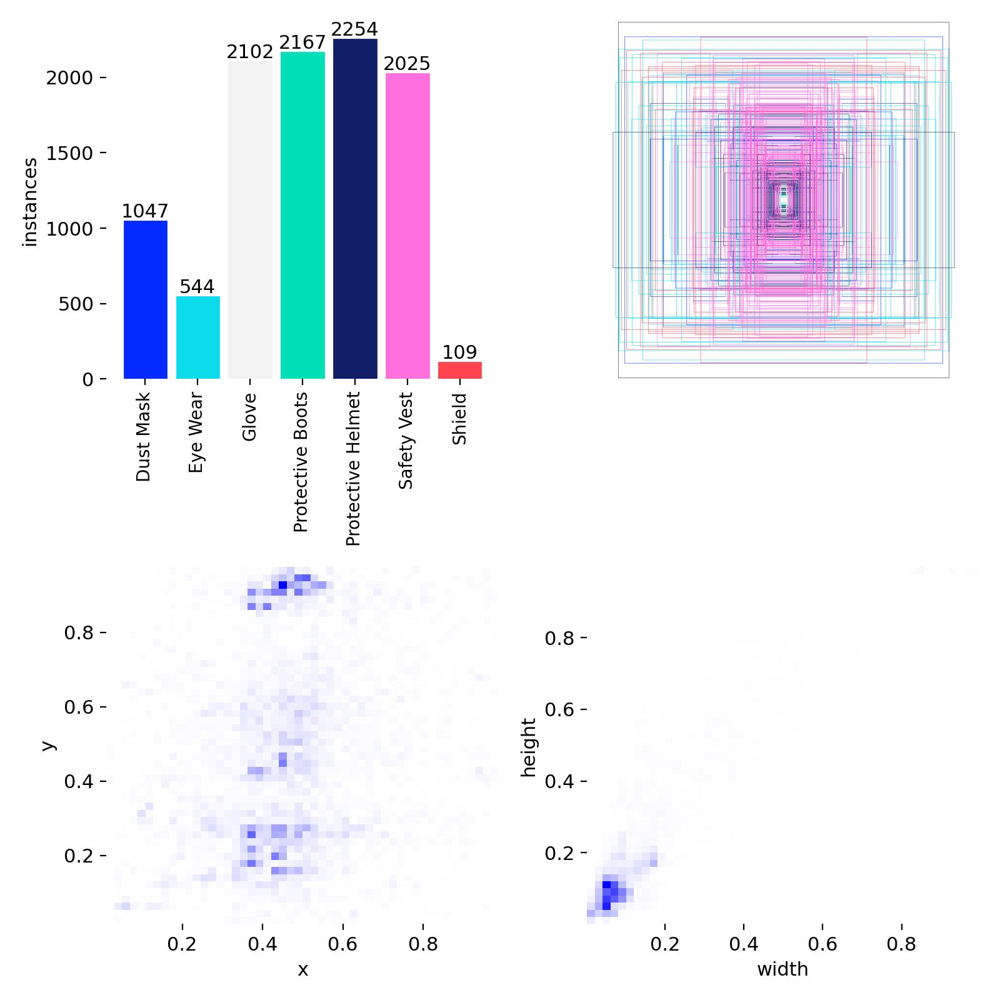

In [11]:
Image("/content/runs/detect/train/labels.jpg", width=600)

This visualization summarizes the dataset distribution for object detection training.  
- The bar chart shows **Safety Vest**, **Protective Helmet**, and **Protective Boots** dominate the dataset, while **Shield** and **Eye Wear** have fewer samples, indicating class imbalance.  
- The bounding box overlay suggests varied object sizes and positions, confirming diverse spatial coverage.  
- The heatmaps reveal most objects cluster near the image center with moderate width–height ratios, typical for person-centered detection tasks.

### 📉 Training & Validation Metrics Overview

Displays `results.png`, the full training log plotted per epoch.

* **Purpose:** Plots box/class/DFL loss for training and validation, along with precision, recall, mAP50 and mAP50-95.
* **Why it matters:** Confirms the model is converging and helps detect overfitting or under-training.

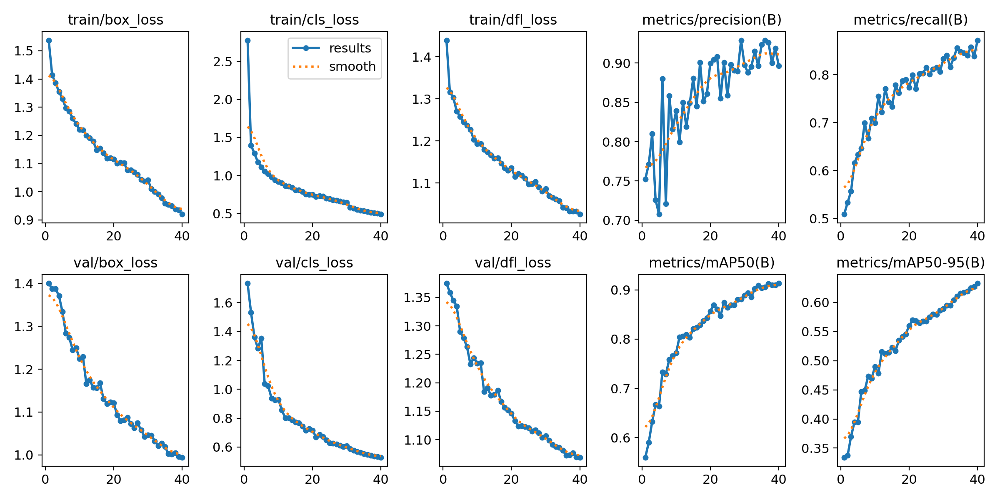

In [12]:
Image("/content/runs/detect/train/results.png", width=600)

These training results show the model is learning effectively.  
- All loss curves (box, class, object) steadily decrease for both training and validation, indicating consistent convergence.  
- Precision and mAP metrics rise sharply, stabilizing near high values, reflecting strong detection accuracy.  
- The upward trend in mAP50 and mAP50–95 confirms improved localization and classification performance across epochs.

###In this step, we are inspecting visual proof of our model's training and prediction data to make sure the AI is learning correctly.
Instead of looking at raw text or number percentages, we are checking the actual image batches that the YOLO model processed.

### 🖼️ Training Batch Sample

Displays `train_batch0.jpg`, a mosaic of images and ground-truth boxes fed to the model during training.

* **Purpose:** Verifies that annotations were loaded correctly and shows the augmentations (mosaic, scaling, flips) applied.

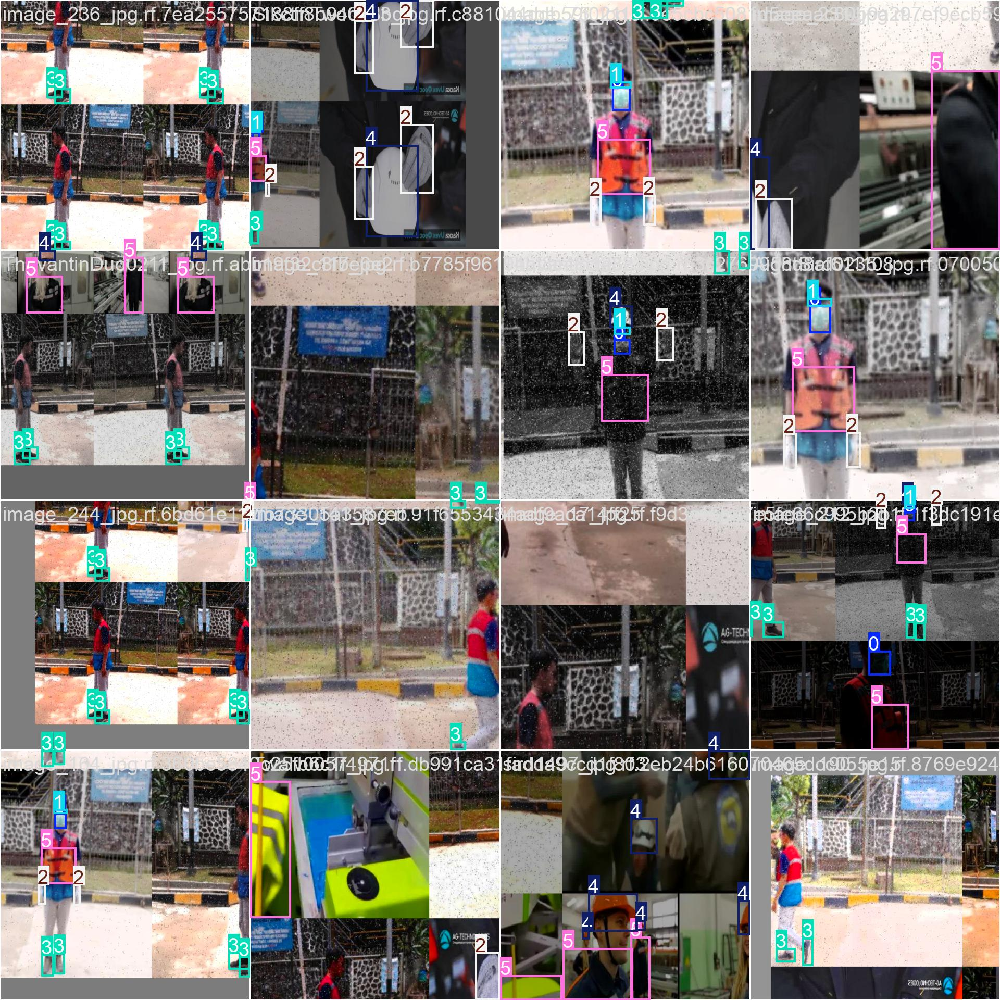

In [13]:
Image("/content/runs/detect/train/train_batch0.jpg", width=600)

### 🔎 Validation Predictions – Batch 0

Displays the model's predictions on the first validation batch.

* **Purpose:** Visually compares predicted boxes and confidence scores against what is actually in the images.

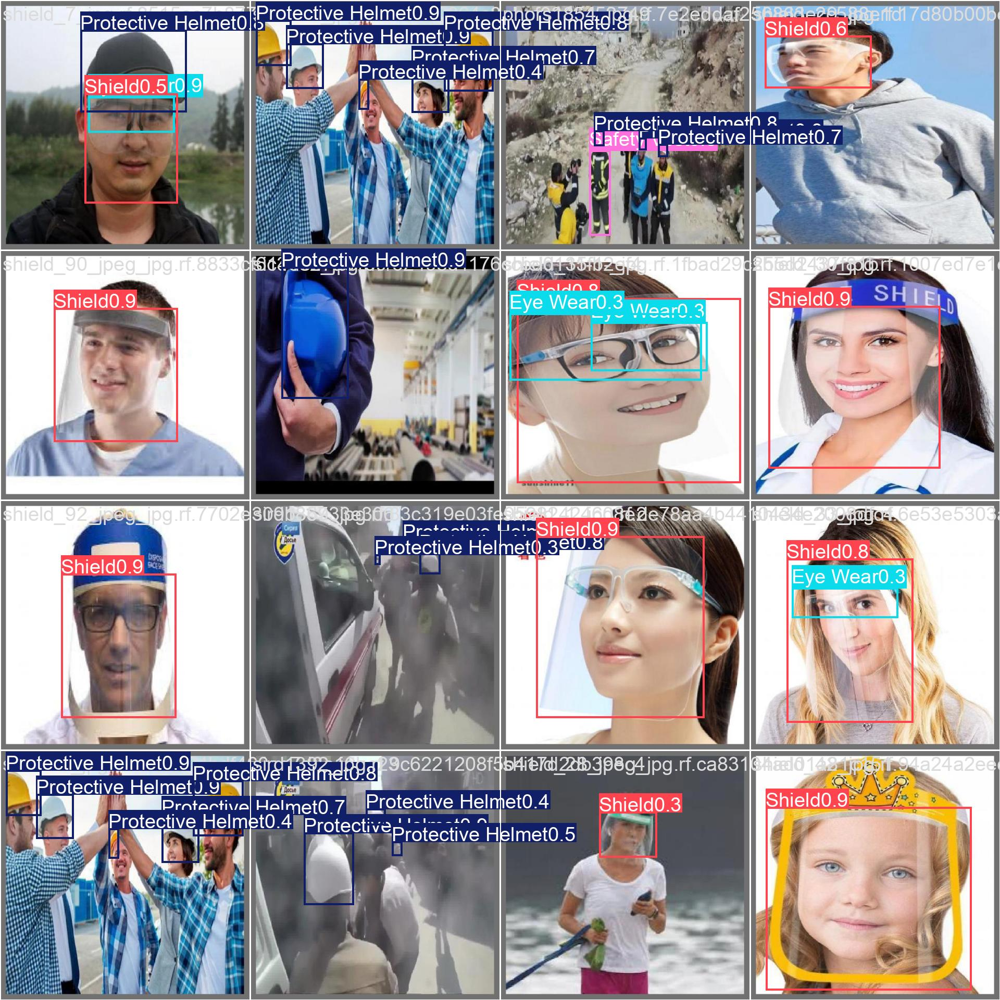

In [14]:
Image("/content/runs/detect/train/val_batch0_pred.jpg", width=600)

### 🔎 Validation Predictions – Batch 1

Displays predictions on the second validation batch for a wider qualitative check of detection quality.

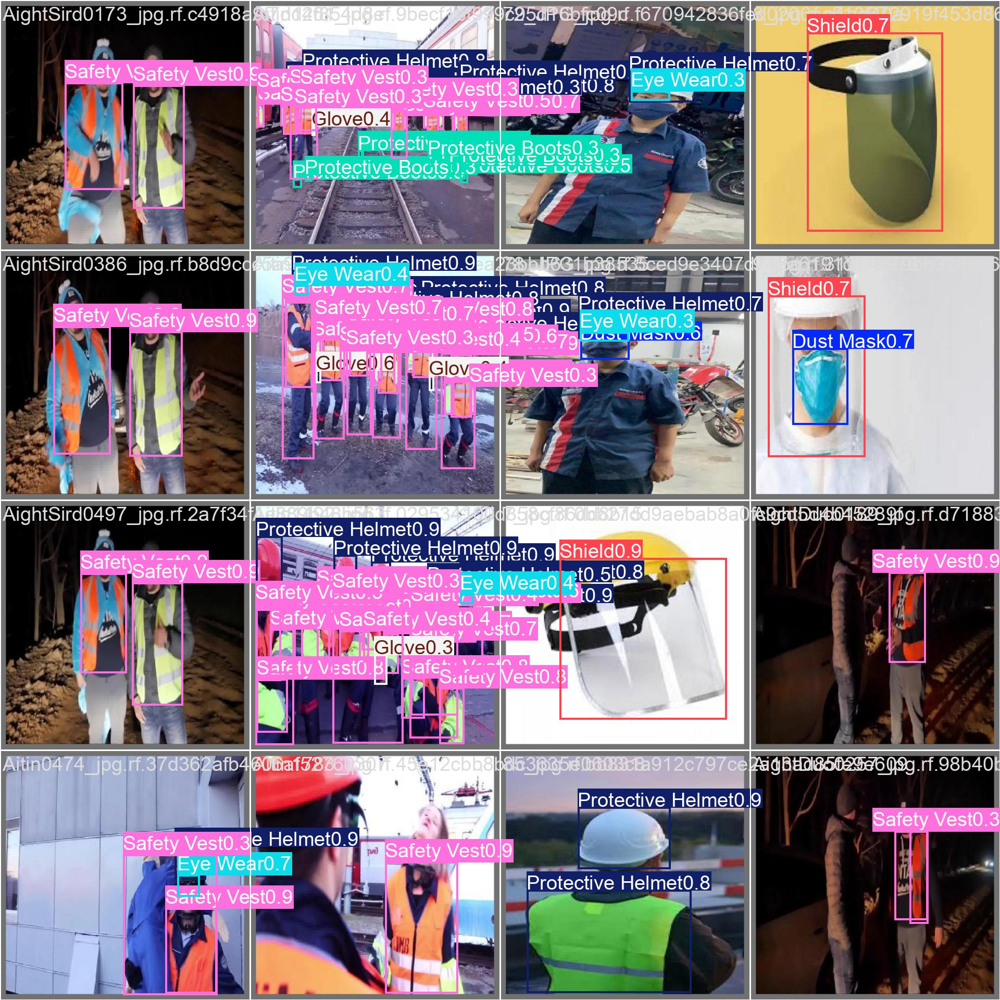

In [15]:
Image("/content/runs/detect/train/val_batch1_pred.jpg", width=600)

### 🔎 Validation Predictions – Batch 2

Displays predictions on the third validation batch, completing the visual review of how the model performs on unseen images.

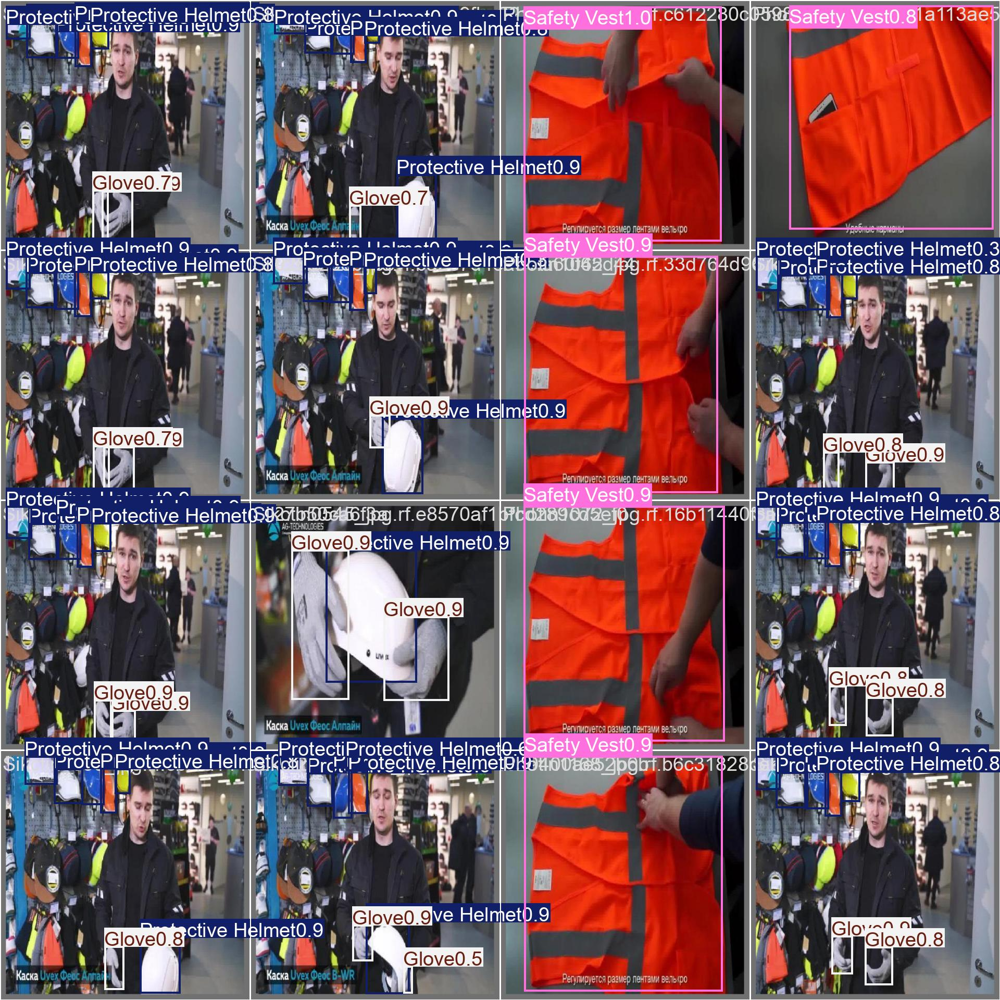

In [16]:
Image("/content/runs/detect/train/val_batch2_pred.jpg", width=600)

**Step # 06 Download the Model Weights from the Google Drive**

### ⬇️ Download Pre-Trained Weights (`best.pt`)

Uses `gdown` to download the model weights file from Google Drive.

* **Purpose:** Fetches `best.pt`, the fine-tuned YOLO weights used for validation and inference in the following steps.
* **`confirm=t`:** Bypasses Google Drive's large-file confirmation prompt.

In [17]:
!gdown "https://drive.google.com/uc?id=1iuIB_3vKBunhyxEPhuecWPAWgVY71BNF&confirm=t"

Downloading...
From: https://drive.google.com/uc?id=1iuIB_3vKBunhyxEPhuecWPAWgVY71BNF&confirm=t
To: /content/best.pt
100% 5.47M/5.47M [00:00<00:00, 37.7MB/s]


The `best.pt` file downloaded above is a highly optimized "brain" obtained from a public repository.

* **Data Collection:** The creators compiled a dataset containing thousands of images specifically focused on **Personal Protective Equipment (PPE)**.
* **Rigorous Training:** They dedicated hours—potentially days—of computational power to train a **YOLO AI model** on their local systems.
* **Purpose:** Instead of training a model from scratch, we are leveraging these pre-trained, fine-tuned weights to achieve **more optimized, faster, and highly accurate detection** for our project.

**Step # 07  Validate Fine-Tuned Model**

### ✅ Model Validation

Runs YOLO in **validation mode** with `best.pt` on the dataset defined in `data.yaml`.

* **Purpose:** Computes the official evaluation metrics: Precision, Recall, mAP50 and mAP50-95, overall and per class.
* **Why it matters:** Gives quantitative proof of how accurate the fine-tuned model is.

In [18]:
!yolo task=detect mode=val model="best.pt" data={dataset.location}/data.yaml

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,517 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1902.3±714.6 MB/s, size: 60.6 KB)
val: Scanning /content/PPE_Detection-2/valid/labels.cache... 637 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 637/637 116.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 4.5it/s 8.9s
                   all        637       3064      0.905      0.847      0.904      0.621
             Dust Mask        299        308      0.982      0.899      0.956      0.663
              Eye Wear        146        147      0.865      0.728      0.777       0.44
                 Glove        346        631      0.966      0.883      0.941      0.663
      Protective Boots        298        608      0.968      0.961      0.979       0.68
     Protective Helmet        403   

**Step # 08 Inference with Custom Model on Images**


### 🖼️ Run Inference on Test Images

Runs YOLO in **predict mode** on every image in the test folder.

* **`conf=0.25`:** Only detections with at least 25% confidence are kept.
* **`save=True`:** Saves annotated images (boxes + labels) to `runs/detect/predict*`.

In [19]:
!yolo task=detect mode=predict model= best.pt conf=0.25 source={dataset.location}/test/images save=True

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,517 parameters, 0 gradients, 6.4 GFLOPs

image 1/322 /content/PPE_Detection-2/test/images/000446_jpg.rf.63a960737ed4b762294eea1ad1a92791.jpg: 640x640 1 Glove, 2 Protective Helmets, 10.6ms
image 2/322 /content/PPE_Detection-2/test/images/20220721_161946_jpg.rf.905c375aa964159f9edab2a55a6e7476.jpg: 640x640 (no detections), 13.3ms
image 3/322 /content/PPE_Detection-2/test/images/20220721_162015_jpg.rf.ccb5d8a5aed0bb50c04431fa0b0d5479.jpg: 640x640 1 Dust Mask, 10.9ms
image 4/322 /content/PPE_Detection-2/test/images/20220721_162036_jpg.rf.2664c2f59604cd2380a51fd174055a7e.jpg: 640x640 1 Dust Mask, 1 Glove, 10.8ms
image 5/322 /content/PPE_Detection-2/test/images/20220721_162308_jpg.rf.913971a6c64f38eabc6b69bab4409b46.jpg: 640x640 1 Dust Mask, 1 Eye Wear, 10.6ms
image 6/322 /content/PPE_Detection-2/test/images/20220721_162435_jpg.rf.d478427044384d4e32ba0c25b15b720d.jpg

### 👀 Display Sample Prediction Results

Finds the most recent `predict` output folder and shows a few annotated test images.

* **How it works:** `glob` lists the result images, `os.path.getmtime` picks the newest folder, and `[1:4]` selects three images to display inline.
* **Purpose:** Quick visual inspection of detections without opening files manually.

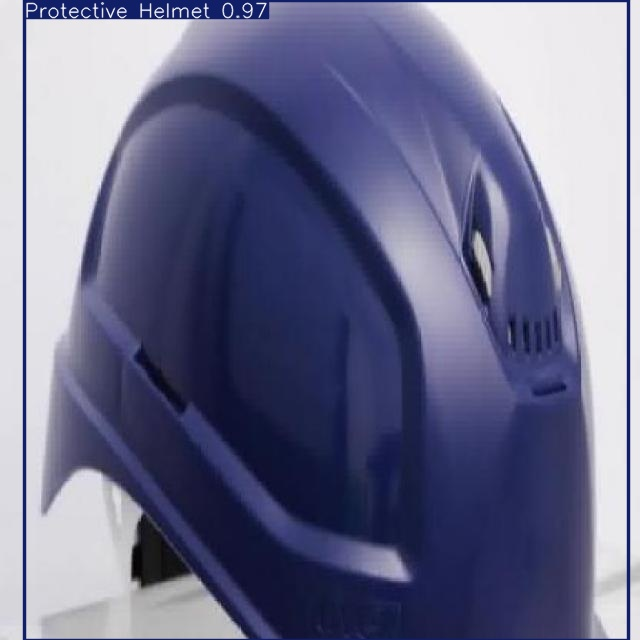

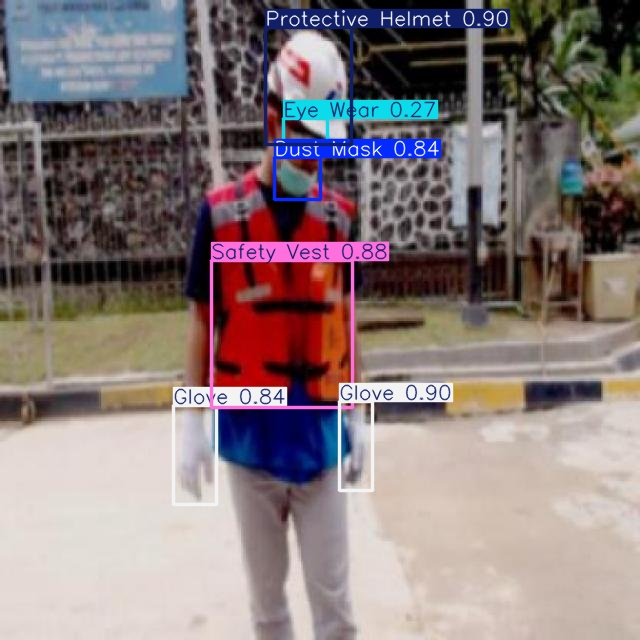

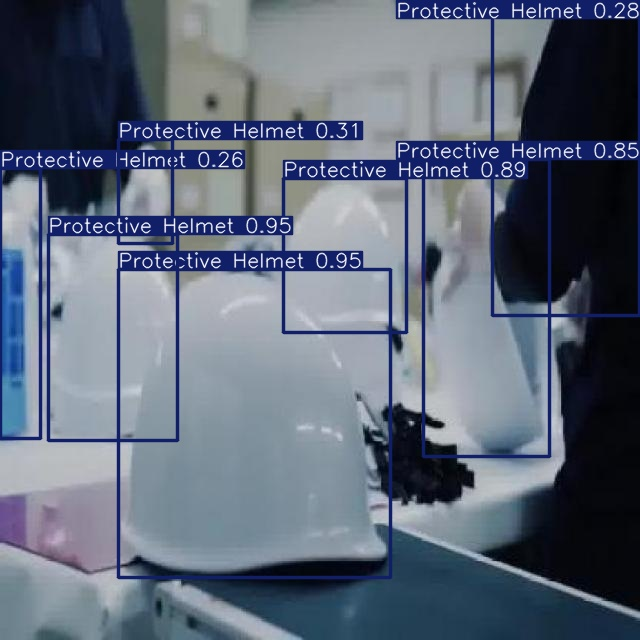

In [20]:
import glob
import os
from IPython.display import Image as IPyImage, display

latest_folder = max(glob.glob('/content/runs/detect/predict*/'), key=os.path.getmtime)
for img in glob.glob(f'{latest_folder}/*.jpg')[1:4]:
    display(IPyImage(filename=img, width=600))
    print("\n")

### ⬇️ Download a Custom Test Image

Downloads `image2.jpg` from Google Drive so the model can be tested on an image outside the dataset.

In [21]:
!gdown "https://drive.google.com/uc?id=1ACZp9gmtjEdIY-SHp8K0xdR0D8Gjd3j3&confirm=t"

Downloading...
From: https://drive.google.com/uc?id=1ACZp9gmtjEdIY-SHp8K0xdR0D8Gjd3j3&confirm=t
To: /content/image2.jpg
100% 77.7k/77.7k [00:00<00:00, 72.4MB/s]


### 🖼️ Run Inference on the Custom Image

Runs the model on `image2.jpg` with a 0.25 confidence threshold and saves the annotated output.

In [22]:
!yolo task=detect mode=predict model= best.pt conf=0.25 source=image2.jpg save=True

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,517 parameters, 0 gradients, 6.4 GFLOPs

image 1/1 /content/image2.jpg: 640x640 6 Protective Bootss, 3 Protective Helmets, 8 Safety Vests, 8.9ms
Speed: 37.9ms preprocess, 8.9ms inference, 19.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-2
💡 Learn more at https://docs.ultralytics.com/modes/predict


### 👀 View the Custom Image Result

Displays the annotated output image produced by the previous cell, showing detected PPE items with class labels and confidence scores.

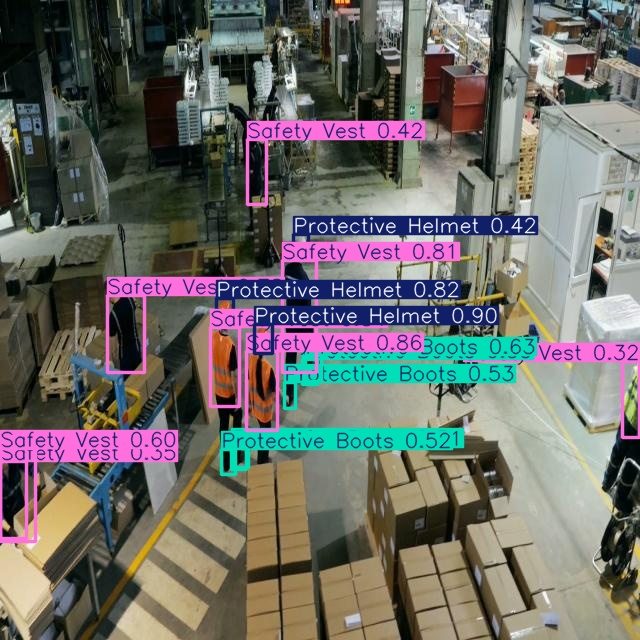

In [23]:
Image("/content/runs/detect/predict-2/image2.jpg", width=600)

**Step # 08 Inference with Custom Model on Videos**

### ⬇️ Download Test Video 1

Downloads the first sample workplace video (`PPE_Part1.mp4`) from Google Drive.

In [24]:
!gdown "https://drive.google.com/uc?id=1Nyl18zr7zOJHh8uHtSic3dsJSY4LI_t-&confirm=t"

Downloading...
From: https://drive.google.com/uc?id=1Nyl18zr7zOJHh8uHtSic3dsJSY4LI_t-&confirm=t
To: /content/PPE_Part1.mp4
100% 14.2M/14.2M [00:00<00:00, 212MB/s]


### ⬇️ Download Test Video 2

Downloads the second sample workplace video (`PPE_Part2.mp4`) from Google Drive.

In [25]:
!gdown "https://drive.google.com/uc?id=1SxcrDanPAr-PZfJjWBxoa2t8lUSM2dZn&confirm=t"

Downloading...
From: https://drive.google.com/uc?id=1SxcrDanPAr-PZfJjWBxoa2t8lUSM2dZn&confirm=t
To: /content/PPE_Part2.mp4
100% 11.1M/11.1M [00:00<00:00, 62.9MB/s]


### 🎥 Run Inference on Video 1

Runs the model frame-by-frame on `PPE_Part1.mp4` and saves the annotated video.

* **Note:** YOLO saves the output as an `.avi` file inside `runs/detect/predict*`.

In [26]:
!yolo task=detect mode=predict model= best.pt conf=0.25 source="PPE_Part1.mp4" save=True

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,517 parameters, 0 gradients, 6.4 GFLOPs

video 1/1 (frame 1/310) /content/PPE_Part1.mp4: 384x640 2 Protective Helmets, 3 Safety Vests, 8.7ms
video 1/1 (frame 2/310) /content/PPE_Part1.mp4: 384x640 2 Protective Helmets, 2 Safety Vests, 11.6ms
video 1/1 (frame 3/310) /content/PPE_Part1.mp4: 384x640 3 Protective Helmets, 2 Safety Vests, 12.8ms
video 1/1 (frame 4/310) /content/PPE_Part1.mp4: 384x640 3 Protective Helmets, 2 Safety Vests, 15.3ms
video 1/1 (frame 5/310) /content/PPE_Part1.mp4: 384x640 3 Protective Helmets, 2 Safety Vests, 12.8ms
video 1/1 (frame 6/310) /content/PPE_Part1.mp4: 384x640 3 Protective Helmets, 2 Safety Vests, 13.2ms
video 1/1 (frame 7/310) /content/PPE_Part1.mp4: 384x640 4 Protective Helmets, 3 Safety Vests, 13.7ms
video 1/1 (frame 8/310) /content/PPE_Part1.mp4: 384x640 3 Protective Helmets, 4 Safety Vests, 11.8ms
video 1/1 (frame 9/310) /

### 🧹 Remove Old Compressed Video

Deletes any previously created `result_compressed.mp4` so the next step writes a fresh file and never shows an outdated result.

In [27]:
!rm '/content/result_compressed.mp4'

rm: cannot remove '/content/result_compressed.mp4': No such file or directory


### 📺 Compress & Play Video 1 Result

Makes the annotated video playable inside the notebook.

* **Locate:** Automatically finds the newest `predict` folder and the `PPE_Part1.avi` output.
* **Compress:** Uses `ffmpeg` to re-encode the `.avi` into browser-friendly H.264 `.mp4`.
* **Display:** Encodes the video as base64 and embeds it in an HTML `<video>` player. A clear error message is printed if the file is missing.

In [28]:
from IPython.display import HTML, display
from base64 import b64encode
import os

# 1. Automatically search for the processed video file
possible_dirs = sorted([d for d in os.listdir('/content/runs/detect') if d.startswith('predict')], reverse=True)

if not possible_dirs:
    raise FileNotFoundError("Could not find any 'predict' folders in /content/runs/detect. Did you run the prediction cell?")

# Pick the most recent predict folder (e.g., predict3, predict2, or predict)
latest_predict_dir = os.path.join('/content/runs/detect', possible_dirs[0])
save_path = os.path.join(latest_predict_dir, 'PPE_Part1.avi')

print(f"Looking for processed video at: {save_path}")

# 2. Path where the compressed video will be saved
compressed_path = "/content/result_compressed.mp4"

# Remove any old file if it exists
if os.path.exists(compressed_path):
    os.remove(compressed_path)

# 3. Correctly format and run the ffmpeg command using f-string
print("Compressing video... please wait...")
os.system(f"ffmpeg -y -i {save_path} -vcodec libx264 {compressed_path}")

# 4. Display the video inside Colab
if os.path.exists(compressed_path):
    mp4 = open(compressed_path, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    display(HTML(f"""
    <video width=500 controls>
          <source src="{data_url}" type="video/mp4">
    </video>
    """))
else:
    print("Error: Compression failed. Please check if your video file actually exists in the predict folder.")


Looking for processed video at: /content/runs/detect/predict-3/PPE_Part1.avi
Compressing video... please wait...


### 🎥 Run Inference on Video 2

Runs the model on `PPE_Part2.mp4` with a 0.25 confidence threshold and saves the annotated video.

In [29]:
!yolo task=detect mode=predict model=best.pt conf=0.25 source="PPE_Part2.mp4" save=True

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,517 parameters, 0 gradients, 6.4 GFLOPs

video 1/1 (frame 1/267) /content/PPE_Part2.mp4: 384x640 (no detections), 8.4ms
video 1/1 (frame 2/267) /content/PPE_Part2.mp4: 384x640 (no detections), 16.0ms
video 1/1 (frame 3/267) /content/PPE_Part2.mp4: 384x640 (no detections), 12.4ms
video 1/1 (frame 4/267) /content/PPE_Part2.mp4: 384x640 (no detections), 13.7ms
video 1/1 (frame 5/267) /content/PPE_Part2.mp4: 384x640 1 Protective Helmet, 1 Safety Vest, 13.2ms
video 1/1 (frame 6/267) /content/PPE_Part2.mp4: 384x640 (no detections), 13.7ms
video 1/1 (frame 7/267) /content/PPE_Part2.mp4: 384x640 (no detections), 13.2ms
video 1/1 (frame 8/267) /content/PPE_Part2.mp4: 384x640 (no detections), 14.3ms
video 1/1 (frame 9/267) /content/PPE_Part2.mp4: 384x640 (no detections), 14.8ms
video 1/1 (frame 10/267) /content/PPE_Part2.mp4: 384x640 (no detections), 15.5ms
video 1/1 (fr

### 🧹 Remove Old Compressed Video

Clears the previous compressed file so the Video 2 result is written cleanly.

In [30]:
!rm '/content/result_compressed.mp4'

### 📺 Compress & Play Video 2 Result

Same process as Video 1: converts the annotated `.avi` to H.264 `.mp4` with `ffmpeg` and shows it in an inline video player.

* **Note:** The output path (`predict-4`) is hard-coded, so adjust it if your prediction folder has a different name.

In [31]:
from IPython.display import HTML, display
from base64 import b64encode
import os

# Input video path
save_path = '/content/runs/detect/predict-4/PPE_Part2.avi'

# Compressed video path
compressed_path = "/content/result_compressed.mp4"

# Run the compression command (added -y to overwrite cleanly)
print("Compressing video... please wait...")
os.system(f"ffmpeg -y -i {save_path} -vcodec libx264 {compressed_path}")

# Show video cleanly using display()
if os.path.exists(compressed_path):
    mp4 = open(compressed_path, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

    # Using display() explicitly makes the player appear!
    display(HTML(f"""
    <video width="600" controls>
          <source src="{data_url}" type="video/mp4">
    </video>
    """))
    print("Video rendered successfully!")
else:
    print("Error: Video compression failed. Check if the file exists in /content/runs/detect/predict-4/")


Compressing video... please wait...


Video rendered successfully!


### ⬆️ Test on Your Own Video (Upload → Detect → Play)

An end-to-end pipeline for any video from your computer:

1. **Upload:** `files.upload()` opens a file picker and stores the chosen MP4.
2. **Detect:** Runs the YOLO model (`best.pt`, `conf=0.25`) on the uploaded video.
3. **Locate:** Finds the newest `predict` folder and the matching `.avi` output.
4. **Compress:** Converts the result to H.264 `.mp4` with `ffmpeg`.
5. **Display:** Shows the final video in an inline player, or prints an error if something failed.

In [32]:
from google.colab import files
from IPython.display import HTML, display
from base64 import b64encode
import os

# Step 1: Upload the MP4 file from your PC
print("Please select your MP4 video file from your computer:")
uploaded = files.upload()

# Get the name of the file you uploaded
uploaded_file_name = list(uploaded.keys())[0]
print(f"Successfully uploaded: {uploaded_file_name}")

# Step 2: Run the YOLO Object Detection model on your video
print("\nRunning safety gear detection model... please wait...")
# We save the output text log to find the exact folder name
os.system(f"yolo task=detect mode=predict model=best.pt conf=0.25 source='{uploaded_file_name}' save=True")

# Step 3: Find the newest prediction folder automatically
possible_dirs = sorted([d for d in os.listdir('/content/runs/detect') if d.startswith('predict')], reverse=True)
latest_predict_dir = os.path.join('/content/runs/detect', possible_dirs[0])

# YOLO changes the extension from .mp4 to .avi when saving
video_base_name = os.path.splitext(uploaded_file_name)[0]
processed_avi_path = os.path.join(latest_predict_dir, f"{video_base_name}.avi")

# Step 4: Compress the output video so it can play in your browser
compressed_path = "/content/my_pc_video_detected.mp4"
print("\nCompressing the results video...")
os.system(f"ffmpeg -y -i '{processed_avi_path}' -vcodec libx264 '{compressed_path}'")

# Step 5: Display the final video player
if os.path.exists(compressed_path):
    print("\n--- Displaying Your Checked Video ---")
    mp4_bytes = open(compressed_path, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4_bytes).decode()
    display(HTML(f"""
    <video width="600" controls>
          <source src="{data_url}" type="video/mp4">
    </video>
    """))
else:
    print("\nError: Could not display video. Check if the model ran successfully.")


Please select your MP4 video file from your computer:


Saving istockphoto-2270086108-640_adpp_is.mp4 to istockphoto-2270086108-640_adpp_is.mp4
Successfully uploaded: istockphoto-2270086108-640_adpp_is.mp4

Running safety gear detection model... please wait...

Compressing the results video...

--- Displaying Your Checked Video ---


##**Web Interface Development**

###Step 1: Install Gradio

### 📦 Install Gradio

Installs **Gradio** (web UI framework) and **Ultralytics** quietly (`-q`).

* **Purpose:** Gradio turns the Python detection functions into an interactive web app with no front-end coding.

In [41]:
!pip install -q gradio ultralytics

#### Step 2: Creating PPE detection web application

### 🌐 Build & Launch the PPE Detection Web App

This cell builds the full Gradio application in six parts:

1. **Load model:** Searches `/content` for the newest `best.pt`, loads it with YOLO, and prints the class names.
2. **`detect_image`:** Runs detection on one image at the chosen confidence, draws the boxes, and converts BGR→RGB for display.
3. **`detect_video`:** Reads the video frame by frame with OpenCV, runs detection on each frame, writes the annotated frames to a new video, then converts it to H.264 with `ffmpeg` so browsers can play it.
4. **`detect_live`:** Same detection logic applied to webcam frames for real-time monitoring.
5. **Interface:** A Gradio `Blocks` layout with three tabs (Image, Video, Live Webcam), each with input/output components and a confidence slider (0.1–0.9, default 0.4).
6. **Launch:** `demo.queue().launch(share=True)` starts the app and generates a public shareable link.

In [ ]:
import gradio as gr
import cv2
import os
import glob
import tempfile
import numpy as np
from ultralytics import YOLO

# ==================================
# 1. LOAD TRAINED MODEL
# ==================================

model_files = glob.glob(
    "/content/**/best.pt",
    recursive=True
)

if not model_files:
    raise FileNotFoundError(
        "Trained best.pt model not found!"
    )

model_path = max(
    model_files,
    key=os.path.getmtime
)

model = YOLO(model_path)

print("Model loaded:", model_path)
print("Classes:", model.names)


# ==================================
# 2. IMAGE DETECTION
# ==================================

def detect_image(image, confidence):

    if image is None:
        return None

    results = model.predict(
        image,
        conf=confidence,
        imgsz=640,
        verbose=False
    )

    annotated = results[0].plot()

    return cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )


# ==================================
# 3. VIDEO DETECTION
# ==================================

def detect_video(video_path, confidence):

    if video_path is None:
        return None

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise gr.Error("Unable to open video.")

    fps = cap.get(cv2.CAP_PROP_FPS)

    if fps <= 0:
        fps = 25

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    output_path = tempfile.mktemp(
        suffix=".mp4"
    )

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")

    out = cv2.VideoWriter(
        output_path,
        fourcc,
        fps,
        (width, height)
    )

    if not out.isOpened():
        cap.release()
        raise gr.Error("Unable to create output video.")

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        results = model.predict(
            frame,
            conf=confidence,
            imgsz=640,
            verbose=False
        )

        annotated = results[0].plot()

        out.write(annotated)

    cap.release()
    out.release()

    # Convert to browser-compatible H.264
    compatible_path = tempfile.mktemp(
        suffix=".mp4"
    )

    import subprocess

    subprocess.run(
        [
            "ffmpeg", "-y",
            "-i", output_path,
            "-c:v", "libx264",
            "-pix_fmt", "yuv420p",
            "-movflags", "+faststart",
            compatible_path
        ],
        check=True,
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE
    )

    return compatible_path


# ==================================
# 4. LIVE WEBCAM DETECTION
# ==================================

def detect_live(frame, confidence):

    if frame is None:
        return None

    results = model.predict(
        frame,
        conf=confidence,
        imgsz=640,
        verbose=False
    )

    annotated = results[0].plot()

    return cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )


# ==================================
# 5. CREATE WEB INTERFACE
# ==================================

with gr.Blocks(
    title="AI PPE Detection System"
) as demo:

    gr.Markdown(
        """
        # AI-Powered PPE Detection System

        ### Real-Time Workplace Safety Monitoring

        **Developed using YOLO and Computer Vision**

        Detect Personal Protective Equipment
        using images, recorded videos,
        or a live webcam.
        """
    )

    with gr.Tabs():

        # IMAGE TAB
        with gr.Tab("Image Detection"):

            with gr.Row():

                image_input = gr.Image(
                    label="Upload Image",
                    type="numpy"
                )

                image_output = gr.Image(
                    label="Detection Results"
                )

            image_conf = gr.Slider(
                0.1, 0.9,
                value=0.4,
                label="Confidence"
            )

            image_button = gr.Button(
                "Detect PPE",
                variant="primary"
            )

            image_button.click(
                detect_image,
                inputs=[
                    image_input,
                    image_conf
                ],
                outputs=image_output
            )

        # VIDEO TAB
        with gr.Tab("Video Detection"):

            video_input = gr.Video(
                label="Upload Workplace Video"
            )

            video_conf = gr.Slider(
                0.1, 0.9,
                value=0.4,
                label="Confidence"
            )

            video_button = gr.Button(
                "Process Video",
                variant="primary"
            )

            video_output = gr.Video(
                label="Processed PPE Detection Video"
            )

            video_button.click(
                detect_video,
                inputs=[
                    video_input,
                    video_conf
                ],
                outputs=video_output
            )

        # LIVE WEBCAM TAB
        with gr.Tab("Live Webcam Detection"):

            gr.Markdown(
                """
                ### Live PPE Monitoring

                Allow camera access to start
                real-time PPE detection.
                """
            )

            webcam_input = gr.Image(
                sources=["webcam"],
                type="numpy",
                label="Live Camera",
                streaming=True
            )

            webcam_conf = gr.Slider(
                0.1, 0.9,
                value=0.4,
                label="Confidence"
            )

            webcam_output = gr.Image(
                label="Live PPE Detection"
            )

            webcam_input.stream(
                fn=detect_live,
                inputs=[
                    webcam_input,
                    webcam_conf
                ],
                outputs=webcam_output,
                stream_every=0.2,
                time_limit=120
            )

    gr.Markdown(
        """
        ---
        **Final Year AI Project — PPE Detection System**

        Powered by Ultralytics YOLO
        """
    )


# ==================================
# 6. LAUNCH WEBSITE
# ==================================

demo.queue().launch(
    share=True,
    debug=True
)

Model loaded: /content/runs/detect/train/weights/best.pt
Classes: {0: 'Dust Mask', 1: 'Eye Wear', 2: 'Glove', 3: 'Protective Boots', 4: 'Protective Helmet', 5: 'Safety Vest', 6: 'Shield'}
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://60e47fae9f7db4696e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
